# 02 · Propensity scores: inverse probability weighting and matching

Notebook 01 modelled the **outcome**. Here we model the **treatment assignment** instead.
The propensity score $e(x) = P(D=1\mid X=x)$ is a one-number summary of the confounders:
if `X` blocks all back-door paths, so does $e(X)$ (Rosenbaum & Rubin, 1983).

**You will implement:**
- logistic regression by Newton–Raphson (IRLS)
- IPW: Horvitz–Thompson and normalized (Hájek) estimators
- 1-nearest-neighbour propensity matching (ATE and ATT)
- overlap diagnostics: weight distribution and effective sample size

**Library checks:** `statsmodels.Logit` and DoWhy's `propensity_score_weighting` / `propensity_score_matching`.

In [1]:
import warnings
warnings.filterwarnings("ignore")  # silence library deprecation/progress chatter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from dowhy import CausalModel

import causalsim as cs
from causalsim.plotting import use_style, truth_line

use_style()

sim = cs.confounded_binary(n=5_000, ate=2.0, confounding=1.0, seed=0)
df = sim.data
X_cols = ["X1", "X2", "X3"]
D, Y = df.D.to_numpy(), df.Y.to_numpy()
print(sim)

SimResult(n=5000, cols=['X1', 'X2', 'X3', 'D', 'Y'], truth={ate=2, att=2, cate=array(5000,), propensity=array(5000,)})


## 1. From scratch: logistic regression (Newton–Raphson)

Log-likelihood $\ell(\beta)=\sum_i d_i x_i^\top\beta - \log(1+e^{x_i^\top\beta})$.
Gradient $X^\top(d-p)$, Hessian $-X^\top W X$ with $W=\text{diag}(p(1-p))$.
Update $\beta \leftarrow \beta + (X^\top W X)^{-1}X^\top(d-p)$ until it stops moving.

In [2]:
def logistic_fit(X: np.ndarray, d: np.ndarray, tol: float = 1e-10, max_iter: int = 100) -> np.ndarray:
    beta = np.zeros(X.shape[1])
    for _ in range(max_iter):
        p = 1 / (1 + np.exp(-X @ beta))
        grad = X.T @ (d - p)
        H = (X * (p * (1 - p))[:, None]).T @ X
        step = np.linalg.solve(H, grad)
        beta += step
        if np.max(np.abs(step)) < tol:
            break
    return beta


Xc = np.column_stack([np.ones(len(df)), df[X_cols].to_numpy()])
b_logit = logistic_fit(Xc, D)
e_hat = 1 / (1 + np.exp(-Xc @ b_logit))

sm_logit = sm.Logit(D, Xc).fit(disp=0)
np.testing.assert_allclose(b_logit, sm_logit.params, rtol=1e-8)
print("✓ Newton–Raphson logistic regression matches statsmodels.Logit")

✓ Newton–Raphson logistic regression matches statsmodels.Logit


## 2. Check overlap first

IPW divides by $e(x)$ and $1-e(x)$. Units with propensities near 0 or 1 get enormous weights.
Always look at the two propensity distributions before estimating anything.

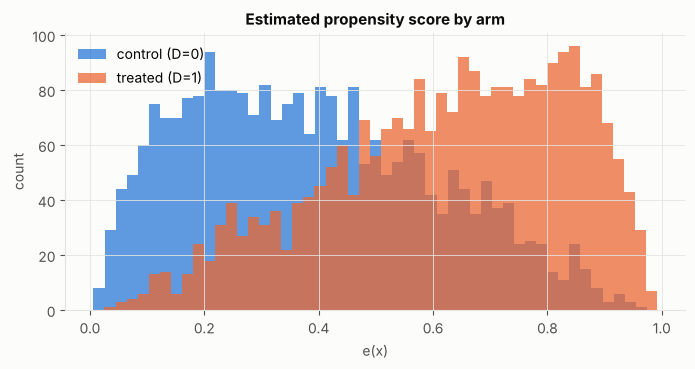

In [3]:
fig, ax = plt.subplots()
ax.hist(e_hat[D == 0], bins=50, alpha=0.75, label="control (D=0)")
ax.hist(e_hat[D == 1], bins=50, alpha=0.75, label="treated (D=1)")
ax.set(title="Estimated propensity score by arm", xlabel="e(x)", ylabel="count")
ax.legend()
plt.show()

## 3. From scratch: IPW

**Horvitz–Thompson:** $\widehat{ATE}=\frac1n\sum \frac{d_iy_i}{e_i}-\frac1n\sum\frac{(1-d_i)y_i}{1-e_i}$

**Hájek (normalized):** divide each arm by the sum of its weights instead of $n$. It is slightly
biased but usually much more stable, because the weights in each arm are forced to sum to 1.

In [4]:
def ipw(d, y, e):
    w1, w0 = d / e, (1 - d) / (1 - e)
    ht = np.mean(w1 * y) - np.mean(w0 * y)
    hajek = np.sum(w1 * y) / np.sum(w1) - np.sum(w0 * y) / np.sum(w0)
    return ht, hajek


def effective_sample_size(w):
    """Kish ESS: how many equally-weighted observations the weights are worth."""
    return w.sum() ** 2 / np.sum(w ** 2)


ht, hajek = ipw(D, Y, e_hat)
w = np.where(D == 1, 1 / e_hat, 1 / (1 - e_hat))
print(f"Horvitz–Thompson: {ht:.3f}   Hájek: {hajek:.3f}   (truth {sim.truth['ate']})")
print(f"max weight {w.max():.1f}; ESS treated {effective_sample_size(w[D==1]):.0f}/{(D==1).sum()}, "
      f"control {effective_sample_size(w[D==0]):.0f}/{(D==0).sum()}")

Horvitz–Thompson: 1.989   Hájek: 1.977   (truth 2.0)
max weight 39.3; ESS treated 1541/2540, control 1537/2460


## 4. From scratch: nearest-neighbour matching on the propensity score

For each treated unit find the control with the closest $e(x)$ (with replacement), and vice versa.
- ATT = mean over treated of $y_i - y_{m(i)}$
- ATC = mean over controls of $y_{m(i)} - y_i$
- ATE = share-weighted average of the two

With one matching variable, a sorted array and `searchsorted` finds neighbours in $O(n\log n)$.

In [5]:
def nearest(src_idx, tgt_idx, score):
    order = np.argsort(score[tgt_idx])
    s_sorted = score[tgt_idx][order]
    pos = np.clip(np.searchsorted(s_sorted, score[src_idx]), 1, len(s_sorted) - 1)
    left, right = s_sorted[pos - 1], s_sorted[pos]
    pick = np.where(np.abs(score[src_idx] - left) <= np.abs(score[src_idx] - right), pos - 1, pos)
    return tgt_idx[order[pick]]


def ps_matching(d, y, e):
    t, c = np.flatnonzero(d == 1), np.flatnonzero(d == 0)
    att = np.mean(y[t] - y[nearest(t, c, e)])
    atc = np.mean(y[nearest(c, t, e)] - y[c])
    ate = (len(t) * att + len(c) * atc) / len(d)
    return ate, att


m_ate, m_att = ps_matching(D, Y, e_hat)
print(f"matching ATE {m_ate:.3f}, ATT {m_att:.3f}   (truth ATE {sim.truth['ate']}, ATT {sim.truth['att']:.3f})")

matching ATE 1.965, ATT 1.984   (truth ATE 2.0, ATT 2.000)


## 5. Library check: DoWhy

Two details matter to get an exact match:
1. DoWhy **clips** propensities to [0.05, 0.95] by default. Pass `min_ps_score=0, max_ps_score=1`
   (or apply the same clipping in your own code).
2. Hand DoWhy the *same* propensity scores via `propensity_score_column`, so any difference comes
   from the estimator and not from the propensity model.

Finding: for the ATE, DoWhy's `ips_weight` already normalizes within each arm, i.e. it is the **Hájek**
estimator, not Horvitz–Thompson. Reading library source code is part of the job.

In [6]:
dw = df.assign(D=df.D.astype(bool), propensity_score=e_hat)
model = CausalModel(data=dw, treatment="D", outcome="Y", common_causes=X_cols)
estimand = model.identify_effect()

dowhy_ipw = model.estimate_effect(
    estimand, method_name="backdoor.propensity_score_weighting", target_units="ate",
    method_params={"weighting_scheme": "ips_weight", "min_ps_score": 0.0, "max_ps_score": 1.0,
                   "propensity_score_column": "propensity_score"},
).value
dowhy_match_ate = model.estimate_effect(
    estimand, method_name="backdoor.propensity_score_matching", target_units="ate",
    method_params={"propensity_score_column": "propensity_score"},
).value
dowhy_match_att = model.estimate_effect(
    estimand, method_name="backdoor.propensity_score_matching", target_units="att",
    method_params={"propensity_score_column": "propensity_score"},
).value

np.testing.assert_allclose(hajek, dowhy_ipw, rtol=1e-10)
np.testing.assert_allclose(m_ate, dowhy_match_ate, rtol=1e-10)
np.testing.assert_allclose(m_att, dowhy_match_att, rtol=1e-10)
print("✓ Hájek IPW and propensity matching (ATE and ATT) match DoWhy exactly")

for est in (ht, hajek, m_ate):
    assert abs(est - sim.truth["ate"]) < 0.15
print("✓ all estimates within 0.15 of the true ATE")

✓ Hájek IPW and propensity matching (ATE and ATT) match DoWhy exactly
✓ all estimates within 0.15 of the true ATE


## 6. Break it

| scenario | what is violated |
|---|---|
| strong confounding (`confounding=3`) | **overlap / positivity**: some units are almost certain to be treated or not |
| non-linear propensity | the logistic model for $e(x)$ is misspecified |
| non-linear outcome | nothing! IPW does not model the outcome, so it should survive |

In [7]:
def run_all(sim):
    d = sim.data
    Dv, Yv = d.D.to_numpy(), d.Y.to_numpy()
    Xv = np.column_stack([np.ones(len(d)), d[X_cols].to_numpy()])
    e = 1 / (1 + np.exp(-Xv @ logistic_fit(Xv, Dv)))
    ht_, hj_ = ipw(Dv, Yv, e)
    w_ = np.where(Dv == 1, 1 / e, 1 / (1 - e))
    return {"truth": sim.truth["ate"], "HT": ht_, "Hájek": hj_, "matching": ps_matching(Dv, Yv, e)[0],
            "max weight": w_.max(), "ESS %": 100 * effective_sample_size(w_) / len(w_)}

scenarios = {
    "baseline": dict(),
    "poor overlap (confounding=3)": dict(confounding=3.0),
    "non-linear propensity": dict(nonlinear_propensity=True),
    "non-linear outcome": dict(nonlinear_outcome=True),
}
pd.DataFrame({k: run_all(cs.confounded_binary(n=20_000, seed=3, **kw)) for k, kw in scenarios.items()}).T.round(3)

,truth,HT,Hájek,matching,max weight,ESS %
baseline,2.0,2.006,2.018,1.999,64.327,65.107
poor overlap (confounding=3),2.0,2.226,2.327,2.184,271.088,9.307
non-linear propensity,2.0,1.561,1.358,1.994,80.707,45.618
non-linear outcome,2.0,1.979,1.991,1.990,64.327,65.107


**What to notice**

- *Poor overlap:* the maximum weight explodes, the effective sample size collapses to a few percent, and every
  estimator drifts. The answer now rests on a handful of units. Remedies are trimming, clipping (what DoWhy does by
  default), or overlap weights, and each one changes the target population.
- *Misspecified propensity:* IPW is clearly biased, even though the outcome model was never involved. Matching
  happens to hold up in this particular simulation; don't count on that in general.
- *Non-linear outcome:* IPW is fine. Compare with notebook 01, where regression adjustment struggled.
  Each family is robust to a different misspecification. Notebook 03 combines them.

**Exercises**
1. Implement trimming (drop units with $e<0.05$ or $e>0.95$) and see how the estimate and target population change.
2. Implement **overlap weights** ($w_1 = 1-e$, $w_0 = e$). Which estimand do they target?
3. Match on the covariates directly (Mahalanobis distance) instead of on $e(x)$. When is that better?
4. Bootstrap the standard error of the Hájek estimator, re-fitting the propensity model in each replicate.